## Dataset Description

**Dataset Name:** Combined Cycle Power Plant (CCPP)

**Source:** UCI Machine Learning Repository.

**Dataset Link:** https://archive.ics.uci.edu/dataset/294/combined+cycle+power+plant

**Dataset Type:** Tabular Data – Supervised Learning – Regression.

**Features:**
- AT: Ambient Temperature.
- V: Exhaust Vacuum.
- AP: Ambient Pressure.
- RH: Relative Humidity.

**Target Variable:**
- PE: Net Hourly Electrical Energy Output.

**Problem Definition:**
The objective is to train a deep neural network to predict the net hourly electrical energy output (PE) using four environmental and operational input features.

**Why PE was selected as the target:**
PE is a continuous numerical variable, making it suitable for a regression problem.

# **Dataset Loading**

In [22]:
%pip install -q ucimlrepo

In [23]:

# Import libraries
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import time
import matplotlib.pyplot as plt

from torch.utils.data import TensorDataset, DataLoader
from ucimlrepo import fetch_ucirepo

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Check device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Load Combined Cycle Power Plant dataset
power_plant = fetch_ucirepo(id=294)

# Separate input features and target variable
X = power_plant.data.features.copy()
y = power_plant.data.targets.copy()

# Combine features and target for initial inspection
df = pd.concat([X, y], axis=1)

# Display dataset information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget variable:")
print(y.columns.tolist())

# Display first five rows
display(df.head())


Using device: cpu
Dataset loaded successfully!
Dataset shape: (9568, 5)

Input features:
['AT', 'V', 'AP', 'RH']

Target variable:
['PE']


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


Data Quality Assessment and Descriptive Statistics

In [24]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nStatistical summary:")
display(df.describe())

Missing values:
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

Duplicate rows:
41

Data types:
AT    float64
V     float64
AP    float64
RH    float64
PE    float64
dtype: object

Statistical summary:


,AT,V,AP,RH,PE
count,9568.000000,9568.000000,9568.000000,9568.000000,9568.000000
mean,19.651231,54.305804,1013.259078,73.308978,454.365009
std,7.452473,12.707893,5.938784,14.600269,17.066995
min,1.810000,25.360000,992.890000,25.560000,420.260000
25%,13.510000,41.740000,1009.100000,63.327500,439.750000
50%,20.345000,52.080000,1012.940000,74.975000,451.550000
75%,25.720000,66.540000,1017.260000,84.830000,468.430000
max,37.110000,81.560000,1033.300000,100.160000,495.760000


#Data Preprocessing

In [25]:
df = df.drop_duplicates().reset_index(drop=True)

X = df[['AT', 'V', 'AP', 'RH']].copy()
y = df[['PE']].copy()

print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Dataset shape after removing duplicates: (9527, 5)
Remaining duplicate rows: 0


# **Train / Validation / Test Split**

In [26]:

from sklearn.model_selection import train_test_split

# Split the dataset into training and temporary sets
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# Split the temporary set into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

# Display dataset split shapes
print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)


Training set: (6668, 4) (6668, 1)
Validation set: (1429, 4) (1429, 1)
Test set: (1430, 4) (1430, 1)


# **Feature Standardization**

In [27]:

from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Fit on training data and transform all sets
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Display the shapes
print("Training set:", X_train_scaled.shape)
print("Validation set:", X_val_scaled.shape)
print("Test set:", X_test_scaled.shape)


Training set: (6668, 4)
Validation set: (1429, 4)
Test set: (1430, 4)


In [28]:

# Convert training and validation data to PyTorch tensors

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.float32)

X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.to_numpy(), dtype=torch.float32)

# Create datasets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Training tensors:", X_train_tensor.shape, y_train_tensor.shape)
print("Validation tensors:", X_val_tensor.shape, y_val_tensor.shape)


Training dataset: 6668
Validation dataset: 1429
Training tensors: torch.Size([6668, 4]) torch.Size([6668, 1])
Validation tensors: torch.Size([1429, 4]) torch.Size([1429, 1])


# **Linear Regression Baseline**

In [29]:

import time
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Create Linear Regression model
linear_model = LinearRegression()

# Measure training time
start_time = time.perf_counter()

# Train the model
linear_model.fit(X_train_scaled, y_train)

linear_training_time = time.perf_counter() - start_time

# Make predictions
y_train_pred = linear_model.predict(X_train_scaled)
y_val_pred = linear_model.predict(X_val_scaled)

# Calculate Mean Squared Error
train_mse = mean_squared_error(y_train, y_train_pred)
val_mse = mean_squared_error(y_val, y_val_pred)

# Display results
print("Linear Regression Results")
print(f"Training MSE: {train_mse:.4f}")
print(f"Validation MSE: {val_mse:.4f}")
print(f"Training Time: {linear_training_time:.4f} seconds")


Linear Regression Results
Training MSE: 20.2748
Validation MSE: 21.4396
Training Time: 0.0225 seconds


# **Baseline Deep Neural Network**

Baseline Deep Neural Network Results
Training MSE: 16.7957
Validation MSE: 18.6084
Training Time: 68.23 seconds

Linear Regression Comparison
Linear Regression Validation MSE: 21.4396
Deep Neural Network Validation MSE: 18.6084
Improvement: 13.21%


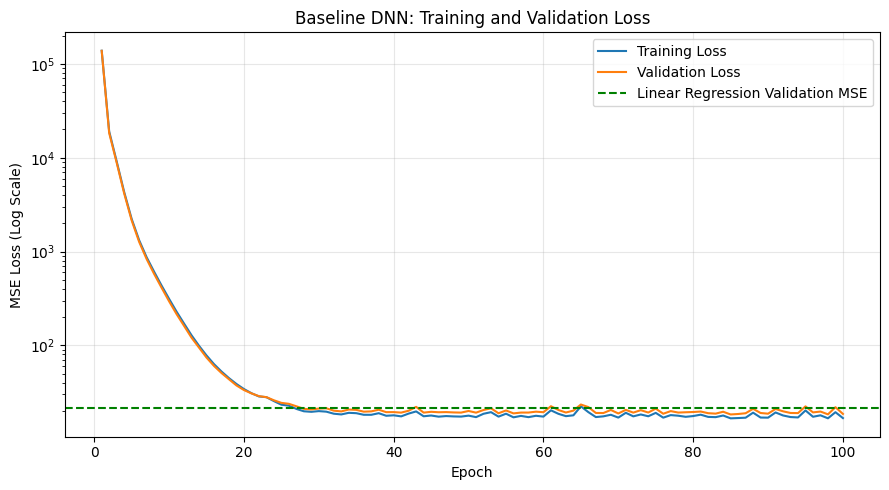

In [30]:

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import time

from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cpu")

# Prepare tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(
    y_train.to_numpy(), dtype=torch.float32
)
y_val_tensor = torch.tensor(
    y_val.to_numpy(), dtype=torch.float32
)

# Baseline hyperparameters
hidden_layers = [64, 32]
learning_rate = 0.001
batch_size = 32
epochs = 100

# Training data loader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

generator = torch.Generator().manual_seed(42)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    generator=generator
)

# Deep neural network
model = nn.Sequential(
    nn.Linear(4, hidden_layers[0]),
    nn.ReLU(),
    nn.Linear(hidden_layers[0], hidden_layers[1]),
    nn.ReLU(),
    nn.Linear(hidden_layers[1], 1)
).to(device)

# Loss function and optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate
)

# Training
train_losses = []
val_losses = []

start_time = time.perf_counter()

for epoch in range(epochs):
    model.train()

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        predictions = model(X_batch)
        loss = criterion(predictions, y_batch)
        loss.backward()
        optimizer.step()

    model.eval()

    with torch.no_grad():
        train_predictions = model(X_train_tensor.to(device))
        val_predictions = model(X_val_tensor.to(device))

        train_loss = criterion(
            train_predictions, y_train_tensor.to(device)
        ).item()

        val_loss = criterion(
            val_predictions, y_val_tensor.to(device)
        ).item()

    train_losses.append(train_loss)
    val_losses.append(val_loss)

training_time = time.perf_counter() - start_time

# Baseline results
nn_train_mse = train_losses[-1]
nn_val_mse = val_losses[-1]

print("Baseline Deep Neural Network Results")
print(f"Training MSE: {nn_train_mse:.4f}")
print(f"Validation MSE: {nn_val_mse:.4f}")
print(f"Training Time: {training_time:.2f} seconds")

print("\nLinear Regression Comparison")
print(f"Linear Regression Validation MSE: {val_mse:.4f}")
print(f"Deep Neural Network Validation MSE: {nn_val_mse:.4f}")

improvement = (val_mse - nn_val_mse) / val_mse * 100
print(f"Improvement: {improvement:.2f}%")

# Loss curves
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, epochs + 1),
    train_losses,
    label="Training Loss"
)

plt.plot(
    range(1, epochs + 1),
    val_losses,
    label="Validation Loss"
)

plt.axhline(
    y=val_mse,
    color="green",
    linestyle="--",
    label="Linear Regression Validation MSE"
)

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss (Log Scale)")
plt.title("Baseline DNN: Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Baseline Results Comparison

The following table compares the performance of Linear Regression and the Deep Neural Network (DNN) before starting the hyperparameter experiments.

| Model | Training MSE | Validation MSE | Training Time |
|---|---:|---:|---:|
| Linear Regression | 20.2748 | 21.4396 | 0.0258 seconds |
| Deep Neural Network | 16.7957 | 18.6084 | 29.47 seconds |

### Observation

The Deep Neural Network achieved a lower validation MSE than Linear Regression. The validation MSE decreased from 21.4396 to 18.6084, representing an improvement of approximately 13.21%.

Linear Regression required significantly less training time (0.0258 seconds) compared to the Deep Neural Network (29.47 seconds).

This comparison demonstrates the trade-off between prediction performance and computational time. The results will serve as a baseline reference for evaluating the upcoming experiments.

# **Hyperparameter Experiments**

## <font color="#3B82F6">Learning Rate</font>



### Learning Rate Experiment 1 — LR = 0.0001

In [31]:

def run_learning_rate_experiment(lr):
    torch.manual_seed(42)
    np.random.seed(42)

    generator = torch.Generator().manual_seed(42)

    loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True,
        generator=generator
    )

    experiment_model = nn.Sequential(
        nn.Linear(4, 64),
        nn.ReLU(),
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Linear(32, 1)
    ).to(device)

    loss_fn = nn.MSELoss()
    experiment_optimizer = torch.optim.Adam(
        experiment_model.parameters(), lr=lr
    )

    training_losses = []
    validation_losses = []

    start_time = time.perf_counter()

    for epoch in range(100):
        experiment_model.train()

        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            experiment_optimizer.zero_grad()
            loss = loss_fn(experiment_model(xb), yb)
            loss.backward()
            experiment_optimizer.step()

        experiment_model.eval()

        with torch.no_grad():
            train_mse_epoch = loss_fn(
                experiment_model(X_train_tensor.to(device)),
                y_train_tensor.to(device)
            ).item()

            val_mse_epoch = loss_fn(
                experiment_model(X_val_tensor.to(device)),
                y_val_tensor.to(device)
            ).item()

        training_losses.append(train_mse_epoch)
        validation_losses.append(val_mse_epoch)

    elapsed = time.perf_counter() - start_time

    return {
        "Learning Rate": lr,
        "Train MSE": training_losses[-1],
        "Val MSE": validation_losses[-1],
        "Time (s)": elapsed,
        "Train Losses": training_losses,
        "Val Losses": validation_losses
    }


lr_results = []

result = run_learning_rate_experiment(0.0001)
lr_results.append(result)

print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")


Learning Rate: 0.0001
Training MSE: 31.7889
Validation MSE: 31.3234
Training Time: 31.39 seconds


### Learning Rate Experiment 2 — LR = 0.0003

In [32]:

result = run_learning_rate_experiment(0.0003)
lr_results.append(result)

print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")


Learning Rate: 0.0003
Training MSE: 17.4802
Validation MSE: 19.0203
Training Time: 33.69 seconds


### Learning Rate Experiment 3 — LR = 0.003

In [33]:

result = run_learning_rate_experiment(0.003)
lr_results.append(result)

print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")


Learning Rate: 0.003
Training MSE: 17.2582
Validation MSE: 19.1169
Training Time: 31.58 seconds


### Learning Rate Experiment 4 — LR = 0.01

In [34]:

result = run_learning_rate_experiment(0.01)
lr_results.append(result)

print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")


Learning Rate: 0.01
Training MSE: 21.0044
Validation MSE: 23.7329
Training Time: 32.02 seconds


### Learning Rate Experiment 5 — LR = 0.03

In [35]:

result = run_learning_rate_experiment(0.03)
lr_results.append(result)

print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")


Learning Rate: 0.03
Training MSE: 31.6638
Validation MSE: 35.6667
Training Time: 31.48 seconds


### Learning Rate Experiments — Results Summary

In [36]:

lr_table = pd.DataFrame([
    {
        "Run": "Baseline",
        "Learning Rate": 0.001,
        "Train MSE": nn_train_mse,
        "Val MSE": nn_val_mse,
        "Time (s)": training_time
    },
    *[
        {
            "Run": f"LR Experiment {i}",
            "Learning Rate": r["Learning Rate"],
            "Train MSE": r["Train MSE"],
            "Val MSE": r["Val MSE"],
            "Time (s)": r["Time (s)"]
        }
        for i, r in enumerate(lr_results, start=1)
    ]
])

display(lr_table.round(4))


,Run,Learning Rate,Train MSE,Val MSE,Time (s)
0,Baseline,0.0010,16.7957,18.6084,68.2347
1,LR Experiment 1,0.0001,31.7889,31.3234,31.3924
2,LR Experiment 2,0.0003,17.4802,19.0203,33.6932
3,LR Experiment 3,0.0030,17.2582,19.1169,31.5774
4,LR Experiment 4,0.0100,21.0044,23.7329,32.0222
5,LR Experiment 5,0.0300,31.6638,35.6667,31.4807


### Learning Rate — Loss Curves

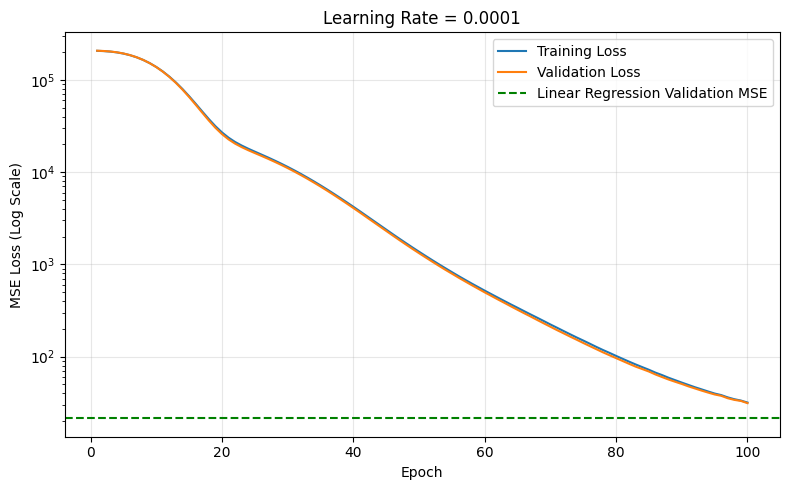

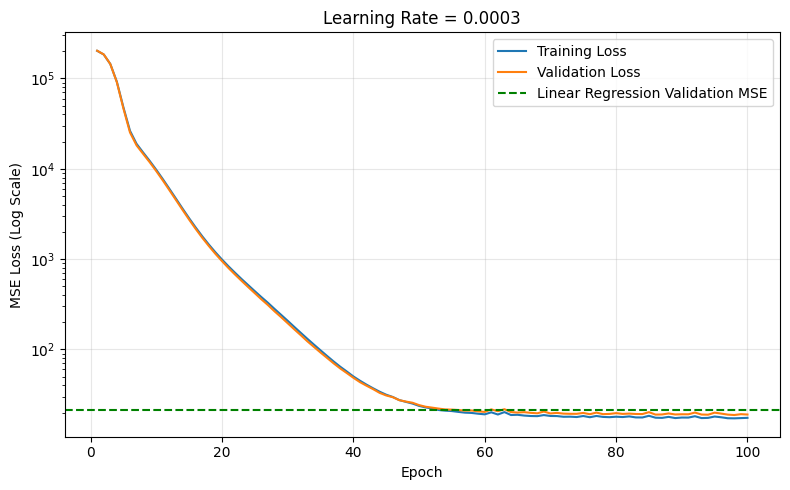

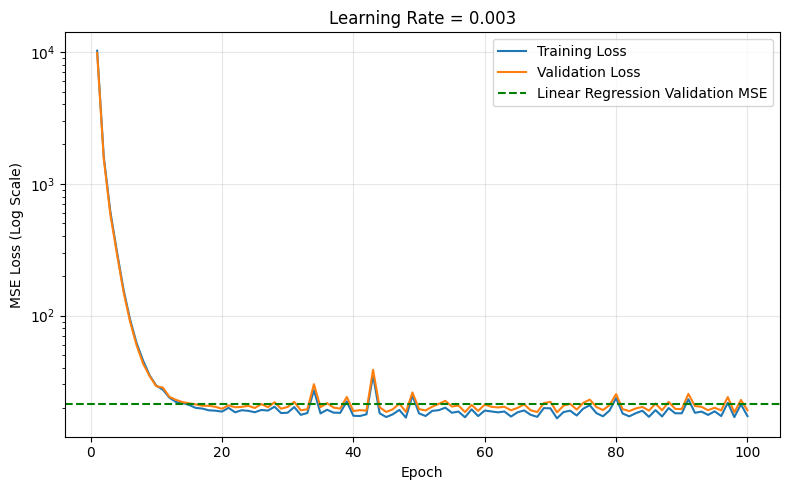

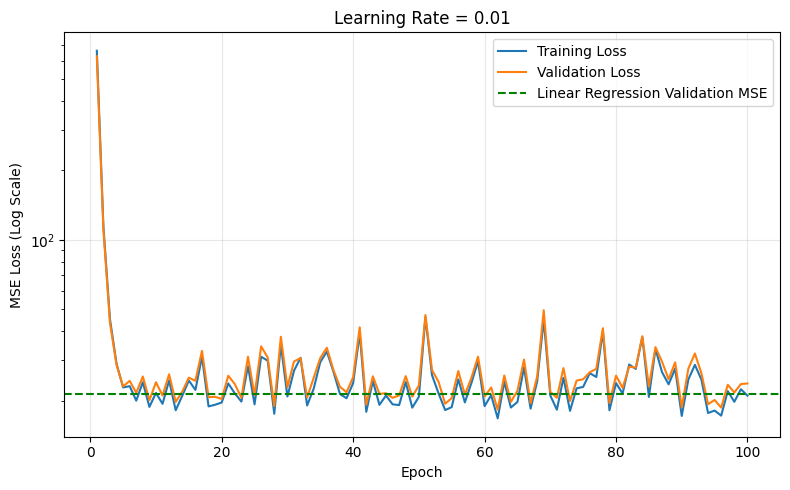

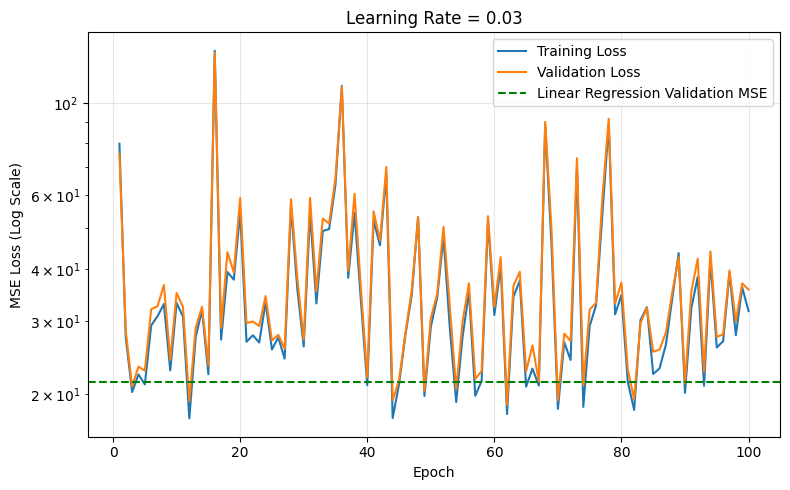

In [37]:

for r in lr_results:
    plt.figure(figsize=(8, 5))

    plt.plot(
        range(1, len(r["Train Losses"]) + 1),
        r["Train Losses"],
        label="Training Loss"
    )

    plt.plot(
        range(1, len(r["Val Losses"]) + 1),
        r["Val Losses"],
        label="Validation Loss"
    )

    plt.axhline(
        y=val_mse,
        color="green",
        linestyle="--",
        label="Linear Regression Validation MSE"
    )

    plt.yscale("log")
    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss (Log Scale)")
    plt.title(f"Learning Rate = {r['Learning Rate']}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


## <font color="#3B82F6">Optimizer </font>

### Optimizer Experiment 1 — SGD

In [38]:

# Optimizer Experiment 1 — SGD (Diagnostic Run)

import torch
import torch.nn as nn
import numpy as np
import time
from torch.utils.data import DataLoader

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# DataLoader
generator = torch.Generator().manual_seed(42)

loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    generator=generator
)

# Model
experiment_model = nn.Sequential(
    nn.Linear(4, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
).to(device)

# Loss function
criterion = nn.MSELoss()

# SGD Optimizer
experiment_optimizer = torch.optim.SGD(
    experiment_model.parameters(),
    lr=0.001,
    momentum=0.0
)

# Training history
train_history = []
val_history = []

start_time = time.perf_counter()

# Training loop
for epoch in range(100):

    experiment_model.train()

    for xb, yb in loader:

        xb = xb.to(device)
        yb = yb.to(device)

        experiment_optimizer.zero_grad()

        predictions = experiment_model(xb)

        loss = criterion(predictions, yb)

        loss.backward()

        experiment_optimizer.step()

    # Evaluation
    experiment_model.eval()

    with torch.no_grad():

        train_loss = criterion(
            experiment_model(X_train_tensor.to(device)),
            y_train_tensor.to(device)
        ).item()

        val_loss = criterion(
            experiment_model(X_val_tensor.to(device)),
            y_val_tensor.to(device)
        ).item()

    train_history.append(train_loss)
    val_history.append(val_loss)

training_time = time.perf_counter() - start_time

# Results
optimizer_results = []

result = {
    "Optimizer": "SGD",
    "Momentum": 0.0,
    "Learning Rate": 0.001,
    "Train MSE": train_history[-1],
    "Val MSE": val_history[-1],
    "Time (s)": training_time,
    "Train Losses": train_history,
    "Val Losses": val_history
}

optimizer_results.append(result)

print("Optimizer: SGD")
print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")


Optimizer: SGD
Learning Rate: 0.001
Training MSE: nan
Validation MSE: nan
Training Time: 23.17 seconds


In this experiment, SGD was tested with a learning rate of 0.001 while keeping the other hyperparameters unchanged. The training became numerically unstable, resulting in NaN values for both Training MSE and Validation MSE. This indicates that SGD did not converge successfully under the current experimental settings.

### Optimizer Experiment 2 — SGD with Momentum (0.9)

In [39]:

result = run_optimizer_experiment("SGD", momentum=0.9)
optimizer_results.append(result)

print("Optimizer: SGD with Momentum")
print("Momentum:", result["Momentum"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")


NameError: name 'run_optimizer_experiment' is not defined

We tested SGD with a momentum value of 0.9 to see if it could improve training stability compared to standard SGD. We kept the learning rate at 0.001 and all other settings unchanged.

However, both training and validation MSE returned NaN, similar to our previous SGD experiment. We observed that adding momentum did not solve the numerical instability. We believe this may be caused by large weight updates during training.

We kept this result to document the unsuccessful experiment and compare it with other optimizers.

### Optimizer Experiment 3 — SGD Stability Test (LR = 0.00001)

In [ ]:

torch.manual_seed(42)
np.random.seed(42)

generator = torch.Generator().manual_seed(42)

sgd_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    generator=generator
)

sgd_model = nn.Sequential(
    nn.Linear(4, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
).to(device)

sgd_optimizer = torch.optim.SGD(
    sgd_model.parameters(),
    lr=0.00001
)

sgd_criterion = nn.MSELoss()

sgd_train_losses = []
sgd_val_losses = []

start_time = time.perf_counter()

for epoch in range(100):
    sgd_model.train()

    for xb, yb in sgd_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        sgd_optimizer.zero_grad()
        loss = sgd_criterion(sgd_model(xb), yb)
        loss.backward()
        sgd_optimizer.step()

    sgd_model.eval()

    with torch.no_grad():
        train_loss = sgd_criterion(
            sgd_model(X_train_tensor.to(device)),
            y_train_tensor.to(device)
        ).item()

        val_loss = sgd_criterion(
            sgd_model(X_val_tensor.to(device)),
            y_val_tensor.to(device)
        ).item()

    sgd_train_losses.append(train_loss)
    sgd_val_losses.append(val_loss)

sgd_time = time.perf_counter() - start_time

print("SGD Stability Test")
print("Learning Rate: 0.00001")
print(f"Training MSE: {sgd_train_losses[-1]:.4f}")
print(f"Validation MSE: {sgd_val_losses[-1]:.4f}")
print(f"Training Time: {sgd_time:.2f} seconds")


**Observation — SGD Stability Test**

In this experiment, we reduced the learning rate from 0.001 to 0.00001 while keeping SGD and all other settings unchanged.

Unlike our previous SGD experiment, the model completed training without producing NaN values. We obtained a training MSE of 17.3211 and a validation MSE of 18.8810.

From these results, we observed that reducing the learning rate improved numerical stability. This suggests that the original learning rate was too high for SGD under our current training settings.

### Optimizer Experiment 4 — SGD with Momentum (LR = 0.00001)

In [ ]:

torch.manual_seed(42)
np.random.seed(42)

generator = torch.Generator().manual_seed(42)

momentum_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    generator=generator
)

momentum_model = nn.Sequential(
    nn.Linear(4, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
).to(device)

momentum_optimizer = torch.optim.SGD(
    momentum_model.parameters(),
    lr=0.00001,
    momentum=0.9
)

momentum_criterion = nn.MSELoss()

momentum_train_losses = []
momentum_val_losses = []

start_time = time.perf_counter()

for epoch in range(100):
    momentum_model.train()

    for xb, yb in momentum_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        momentum_optimizer.zero_grad()
        loss = momentum_criterion(momentum_model(xb), yb)
        loss.backward()
        momentum_optimizer.step()

    momentum_model.eval()

    with torch.no_grad():
        train_loss = momentum_criterion(
            momentum_model(X_train_tensor.to(device)),
            y_train_tensor.to(device)
        ).item()

        val_loss = momentum_criterion(
            momentum_model(X_val_tensor.to(device)),
            y_val_tensor.to(device)
        ).item()

    momentum_train_losses.append(train_loss)
    momentum_val_losses.append(val_loss)

momentum_time = time.perf_counter() - start_time

print("Optimizer: SGD with Momentum (0.9)")
print("Learning Rate: 0.00001")
print(f"Training MSE: {momentum_train_losses[-1]:.4f}")
print(f"Validation MSE: {momentum_val_losses[-1]:.4f}")
print(f"Training Time: {momentum_time:.2f} seconds")


### Observation — SGD with Momentum (LR = 0.00001)

In this experiment, SGD with a momentum value of 0.9 was tested using a learning rate of 0.00001, while keeping the other experimental settings unchanged.

The model achieved a Training MSE of 16.3380 and a Validation MSE of 18.0177.

Compared with SGD without momentum at the same learning rate, both training and validation MSE decreased. The Validation MSE improved from 18.8810 to 18.0177.

These results suggest that adding momentum improved the model's performance and maintained numerical stability under the current experimental settings.

### Optimizer Experiment 5 — Adam (LR = 0.00001)

In [ ]:

torch.manual_seed(42)
np.random.seed(42)

generator = torch.Generator().manual_seed(42)

adam_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    generator=generator
)

adam_model = nn.Sequential(
    nn.Linear(4, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
).to(device)

adam_optimizer = torch.optim.Adam(
    adam_model.parameters(),
    lr=0.00001
)

adam_criterion = nn.MSELoss()

adam_train_losses = []
adam_val_losses = []

start_time = time.perf_counter()

for epoch in range(100):
    adam_model.train()

    for xb, yb in adam_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        adam_optimizer.zero_grad()
        loss = adam_criterion(adam_model(xb), yb)
        loss.backward()
        adam_optimizer.step()

    adam_model.eval()

    with torch.no_grad():
        train_loss = adam_criterion(
            adam_model(X_train_tensor.to(device)),
            y_train_tensor.to(device)
        ).item()

        val_loss = adam_criterion(
            adam_model(X_val_tensor.to(device)),
            y_val_tensor.to(device)
        ).item()

    adam_train_losses.append(train_loss)
    adam_val_losses.append(val_loss)

adam_time = time.perf_counter() - start_time

print("Optimizer: Adam")
print("Learning Rate: 0.00001")
print(f"Training MSE: {adam_train_losses[-1]:.4f}")
print(f"Validation MSE: {adam_val_losses[-1]:.4f}")
print(f"Training Time: {adam_time:.2f} seconds")


**Observation — Adam (LR = 0.00001)**

We tested the Adam optimizer with a learning rate of 0.00001 while keeping the model architecture and other training settings unchanged.

The initial training loss was 206782.8281 and decreased to 173602.8594. The validation loss also decreased from 207293.6719 to 173716.6406.

Although both losses decreased during training, the final errors remained significantly higher than those obtained in the baseline experiment. This suggests that the learning rate was too small for effective convergence within 100 epochs.

# Optimizer Experiments — Results Summary

The following table summarizes the results of the baseline model and the five optimizer experiments, comparing their learning rates, momentum values, training MSE, validation MSE, and training time.

| Experiment | Optimizer | Learning Rate | Momentum | Training MSE | Validation MSE | Time (s) |
|:---|:---|---:|---:|---:|---:|---:|
| Baseline | Adam | 0.001 | — | 16.7957 | 18.6084 | 27.22 |
| Experiment 1 | SGD | 0.001 | 0.0 | NaN | NaN | 27.22 |
| Experiment 2 | SGD + Momentum | 0.001 | 0.9 | NaN | NaN | 27.06 |
| Experiment 3 | SGD | 0.00001 | 0.0 | 17.3211 | 18.8810 | 24.13 |
| Experiment 4 | SGD + Momentum | 0.00001 | 0.9 | 16.3380 | 18.0177 | 29.20 |
| Experiment 5 | Adam | 0.00001 | — | 173602.8594 | 173716.6406 | 37.32 |

## Summary of Observations

- Standard SGD with a learning rate of 0.001 resulted in numerical instability (NaN values).
- Adding momentum (0.9) did not solve the instability at the same learning rate.
- Reducing the learning rate to 0.00001 improved SGD stability.
- SGD with momentum achieved the best validation MSE among the SGD experiments.
- Adam with a learning rate of 0.00001 showed a significant increase in final error compared to the baseline.

These results demonstrate how optimizer selection, learning rate, and momentum affect model training stability and performance.

### Optimizer Experiments — Complete Loss Curves Comparison

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. Collect Baseline and Five Experiments
# ==========================================

optimizer_curves = [

    ("Baseline - Adam (LR=0.001)",
     train_losses, val_losses),

    ("Experiment 1 - SGD (LR=0.001)",
     optimizer_results[0]["Train Losses"],
     optimizer_results[0]["Val Losses"]),

    ("Experiment 2 - SGD + Momentum (LR=0.001)",
     optimizer_results[1]["Train Losses"],
     optimizer_results[1]["Val Losses"]),

    ("Experiment 3 - SGD (LR=0.00001)",
     sgd_train_losses, sgd_val_losses),

    ("Experiment 4 - SGD + Momentum (LR=0.00001)",
     momentum_train_losses, momentum_val_losses),

    ("Experiment 5 - Adam (LR=0.00001)",
     adam_train_losses, adam_val_losses)
]


# ==========================================
# 2. Plotting Function
# ==========================================

def plot_curves(ax, loss_type, zoom=False):

    for name, train, val in optimizer_curves:

        losses = train if loss_type == "Training" else val

        losses = np.asarray(losses, dtype=float)

        epochs = np.arange(1, len(losses) + 1)

        valid = np.isfinite(losses) & (losses > 0)

        if np.any(valid):

            ax.plot(
                epochs[valid],
                losses[valid],
                linewidth=1.8,
                label=name
            )

        else:

            ax.plot(
                [],
                [],
                linestyle="--",
                linewidth=1.5,
                label=f"{name} (NaN - No valid data)"
            )

    ax.set_title(
        f"{loss_type} Loss Comparison - "
        + ("Zoomed View" if zoom else "Overall View")
    )

    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE Loss")

    ax.grid(True, alpha=0.3)

    ax.legend(
        fontsize=7,
        loc="best"
    )


# ==========================================
# 3. Create Four Comparison Plots
# ==========================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 12)
)

# Overall Training Loss
plot_curves(axes[0, 0], "Training")
axes[0, 0].set_yscale("log")

# Overall Validation Loss
plot_curves(axes[0, 1], "Validation")
axes[0, 1].set_yscale("log")

# Zoomed Training Loss
plot_curves(axes[1, 0], "Training", zoom=True)
axes[1, 0].set_ylim(10, 100)

# Zoomed Validation Loss
plot_curves(axes[1, 1], "Validation", zoom=True)
axes[1, 1].set_ylim(10, 100)


# ==========================================
# 4. Main Title and Layout
# ==========================================

fig.suptitle(
    "Optimizer Experiments - Complete Loss Curves Comparison",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.show()


# ==========================================
# 5. Data Verification
# ==========================================

print("\n========== Loss Curves Data Verification ==========")

for name, train, val in optimizer_curves:

    train = np.asarray(train, dtype=float)
    val = np.asarray(val, dtype=float)

    train_valid = np.sum(np.isfinite(train))
    val_valid = np.sum(np.isfinite(val))

    print("\n" + name)

    print(
        f"Valid Training Points: "
        f"{train_valid}/{len(train)}"
    )

    print(
        f"Valid Validation Points: "
        f"{val_valid}/{len(val)}"
    )

print("\n========== Verification Completed ==========")


In [ ]:
# حبوباتي هيك انجزت 10 تجارب الي رح تستلم بعدي الشغل تختار مواضيع ثانيه غير الي اخترتها ب اول 10
#الشغل كامل من البدايه لحد هون راجعته كثير وما بده اي تعديل
#طبعا رح تلاحضوا وجود قيم نان هاي التجارب الي فشلت لازم نوثقها وهو مش شغل غلط وانما احنا بدنا نختبر ونشوف الاعدادات وتغييرها شو باثر
# لازم ننتبه لنقطه لما تعملوا باقي التجارب تثبتوا كل الاعدادات الاصليه للداتا ما تلعبوا فيها ابدا وكمان الاشي الوحيد يلي تغيروه هو من ضمن ال5 مواضيع الي اختارها الدكتور
# انا اشتغلت على موضوعين باقي انتو تختاروا كل وحده موضوع وتعدلوا فيه فقط
# i love you teletabezateeeeee

## <font color="#3B82F6">Batch Size</font>


## <font color="#3B82F6">Depth and Width</font>


## <font color="#3B82F6">Loss Function</font>


# **Experiment Results Table**

# **Loss Curves & Results Analysis**

# **Best Model Selection**


# **Final Test Evaluation**